In [13]:
import numpy as np
import pandas as pd
import pickle
import glob
import os
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.fft import fft, ifft, fftfreq
from scipy.ndimage import gaussian_filter1d


matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
Fs = 3e4
TimeHistory = 20e-3
TimePost = 2e-3
L = int(TimeHistory * Fs)  # 600 samples

out_path = './dataFolder/Whitened_STA/'
os.makedirs(out_path, exist_ok=True)
out_fig = './dataFolder/Figures/Whitened_STA/'
os.makedirs(out_fig, exist_ok=True)

In [3]:
model_files = glob.glob('./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/*.pickle')
wn_files = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_timeStamps_degrees.pickle')

print(f'Found {len(model_files)} model files')
print(f'Found {len(wn_files)} white noise files')

Found 6 model files
Found 4 white noise files


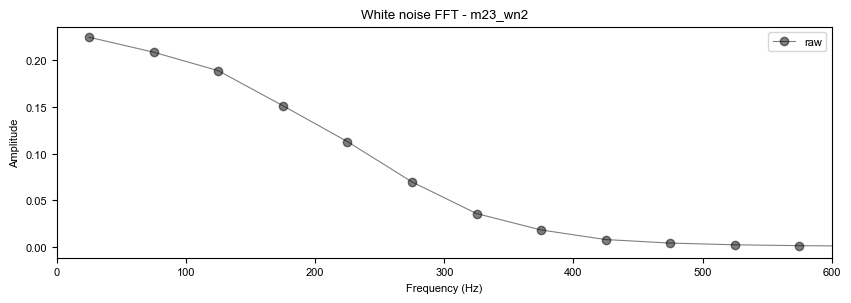

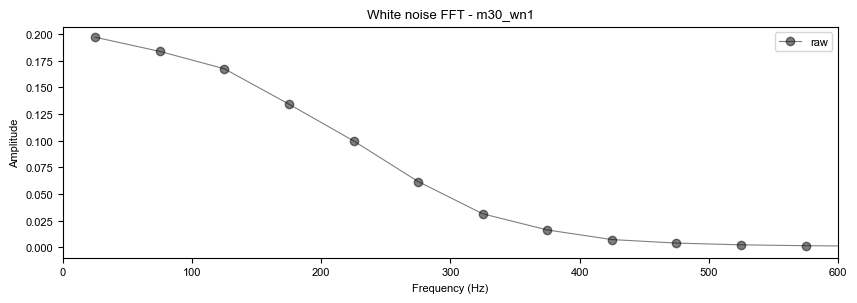

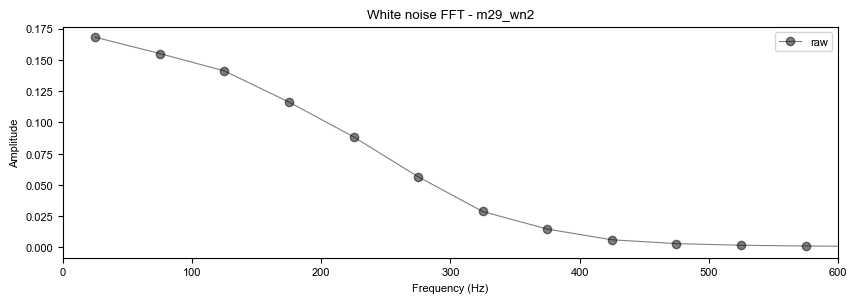

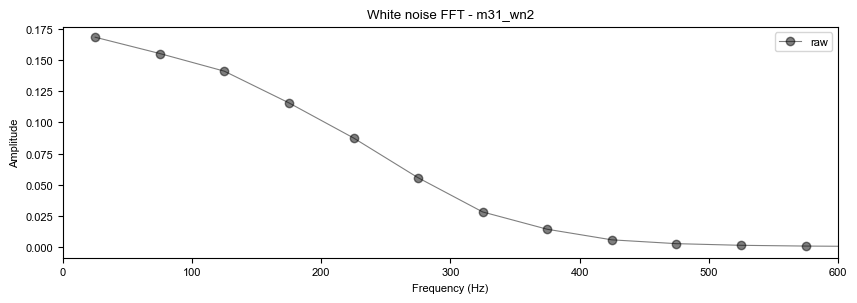

In [80]:
#fft for downsampled white noose
for wn_filepath in wn_files:
    name = '_'.join(os.path.basename(wn_filepath).split('_')[0:2])
    
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    # FFT of full white noise (this is the full sampled length)
    fft_wn_full = np.abs(fft(WhiteNoise, norm = 'forward'))
    fft_wn_full *= 2
    freqs_wn_full = fftfreq(len(WhiteNoise), d=1/Fs)
    
    # downsample here to STA sampling frequency- divide by sta L then chunk and take mean of each chunk
    chunk = len(fft_wn_full) // L
    fft_wn_ds = np.array([fft_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(L)])
    freqs_wn_ds = np.array([freqs_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(L)])
    pos = freqs_wn_ds > 0
    
    # smooth here- made sigma high
    #fft_wn_smooth = gaussian_filter1d(fft_wn_ds, sigma=100)
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_wn_ds[pos], fft_wn_ds[pos], 'o-k', linewidth=0.8, alpha=0.5, label='raw')
    #plt.plot(freqs_wn_ds[pos], fft_wn_smooth[pos], 'r', linewidth=1.5, label='smoothed')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.xlim(0, 600)
    plt.legend()
    plt.title(f'White noise FFT - {name}')
    #plt.savefig(out_fig + name + '_WN_fft.pdf')
    plt.show()
    plt.close()

    time_axis = np.arange(len(WhiteNoise)) / Fs
    
    # plt.figure(figsize=(12, 3))
    # plt.plot(time_axis, WhiteNoise, 'k', linewidth=0.5)
    # plt.xlabel('Time (s)')
    # plt.ylabel('Amplitude (degrees)')
    # plt.title(f'White noise waveform - {name}')
    # plt.show()
    # plt.close()

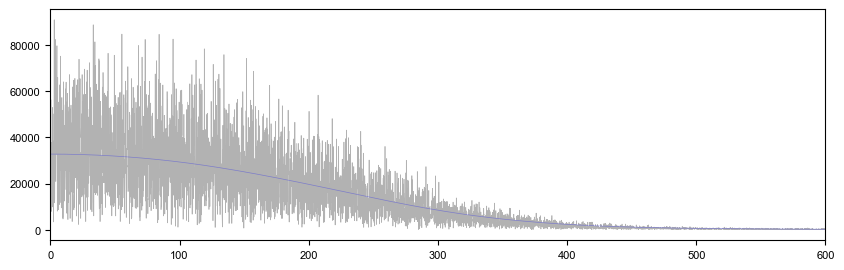

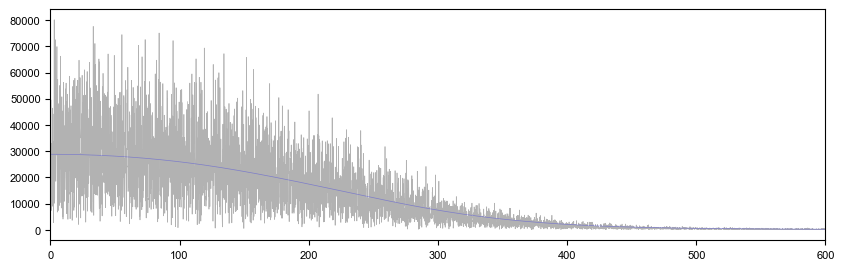

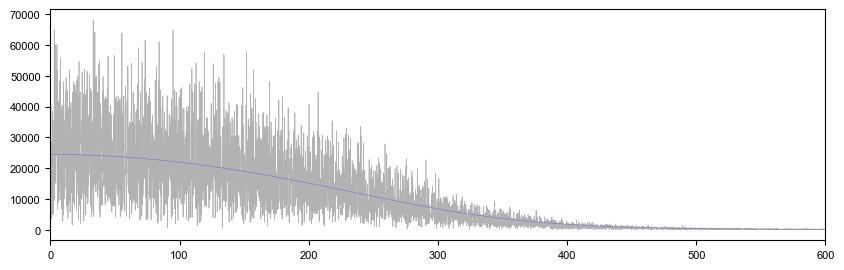

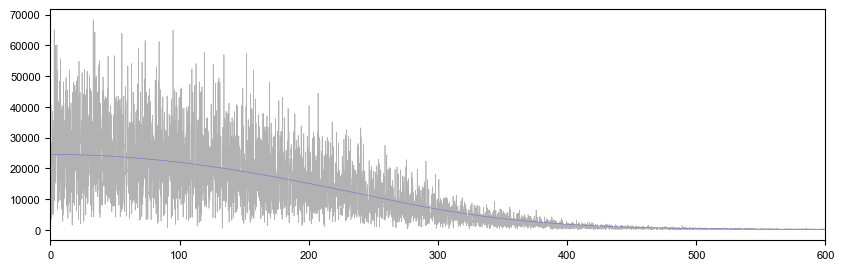

In [81]:
for wn_filepath in wn_files:
    name = '_'.join(os.path.basename(wn_filepath).split('_')[0:2])
    
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    
    fft_wn_full = np.abs(fft(WhiteNoise))
    freqs_wn_full = fftfreq(len(WhiteNoise), d=1/Fs)
    pos_full = freqs_wn_full > 0
    
   
    fft_wn_full_smooth = gaussian_filter1d(fft_wn_full, sigma=500)
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_wn_full[pos_full], fft_wn_full[pos_full], 'k', linewidth=0.5, alpha=0.3)
    plt.plot(freqs_wn_full[pos_full], fft_wn_full_smooth[pos_full], color='blue', linewidth=0.5, alpha=0.3)
    plt.xlim(0, 600)
    

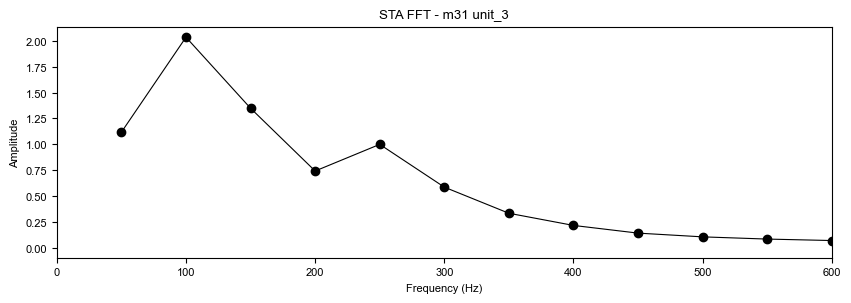

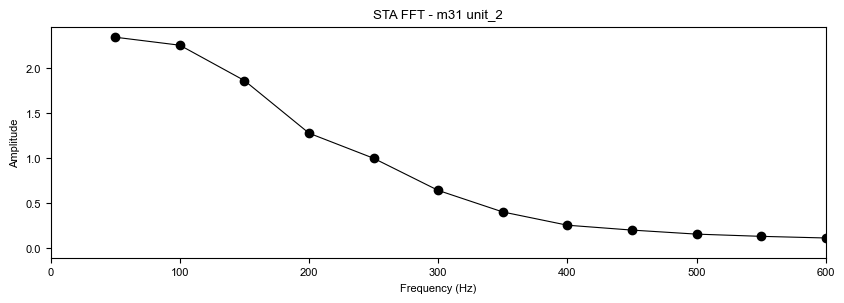

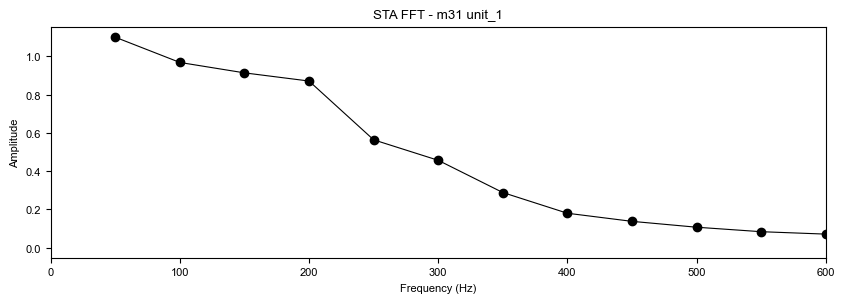

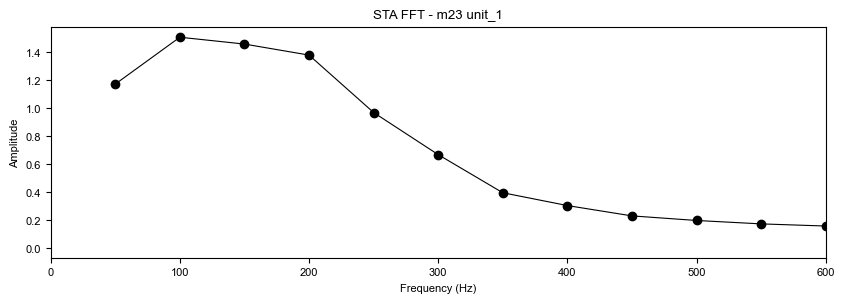

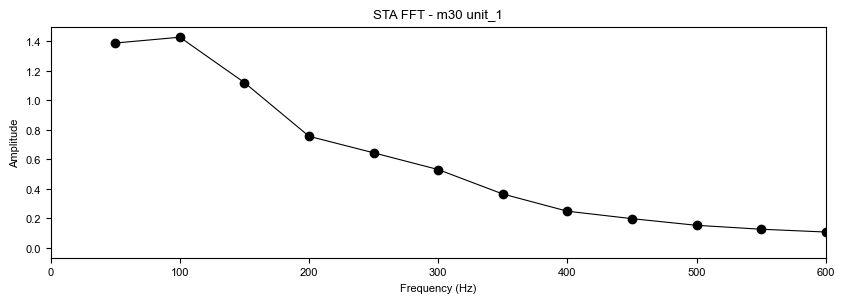

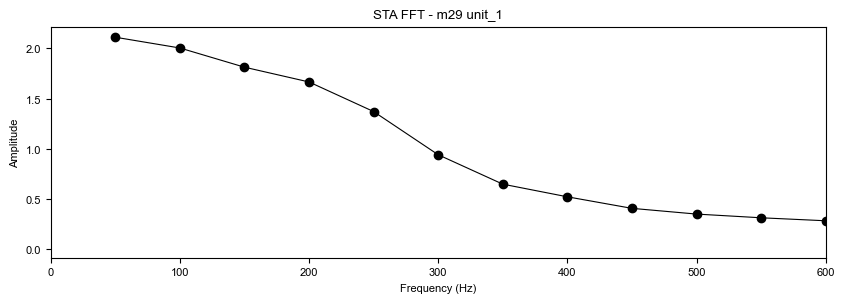

In [82]:
for filepath in model_files:
    name = os.path.basename(filepath).split('_')[0]
    unitID = "_".join(os.path.basename(filepath).split('_')[1:3])
    
    with open(filepath, 'rb') as f:
        savedModel = pickle.load(f)
    sta = savedModel[1][:L]
    
    freqs_sta = fftfreq(L, d=1/Fs)
    pos_sta = freqs_sta > 0
    fft_sta = fft(sta, norm = 'forward')
    fft_sta *= 2
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_sta[pos_sta], np.abs(fft_sta)[pos_sta], 'o-k', linewidth=0.8)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.xlim(0, 600)
    plt.title(f'STA FFT - {name} {unitID}')
    #plt.savefig(out_fig + name + '_' + unitID + '_STA_fft.pdf')
    plt.show()
    plt.close()

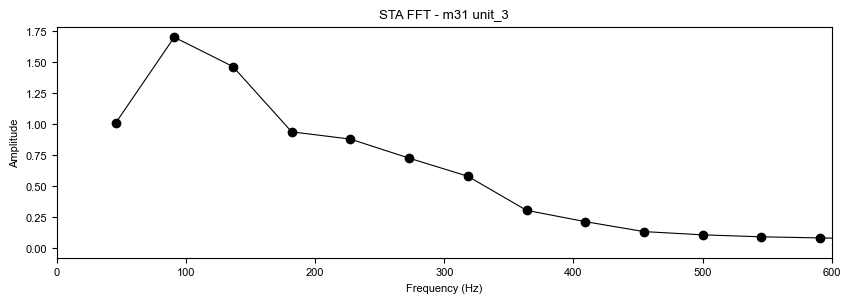

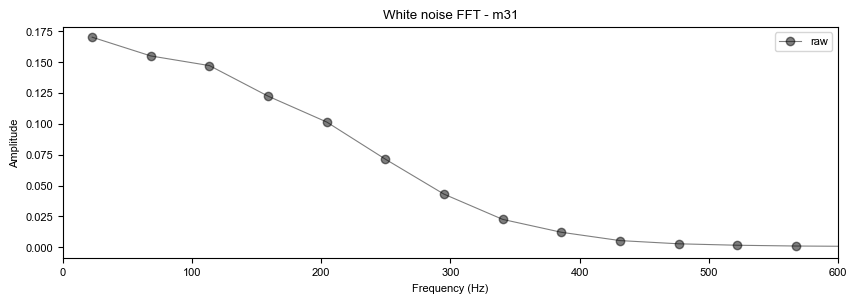

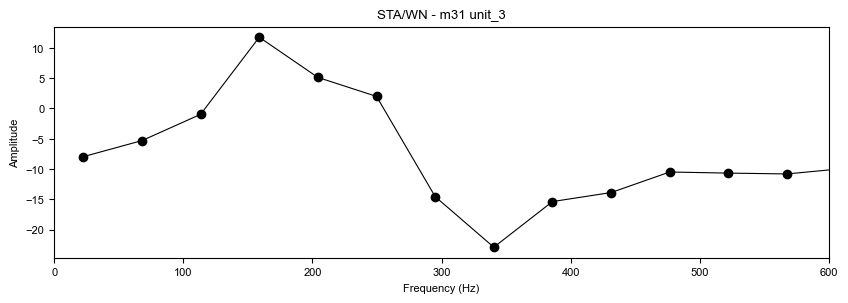

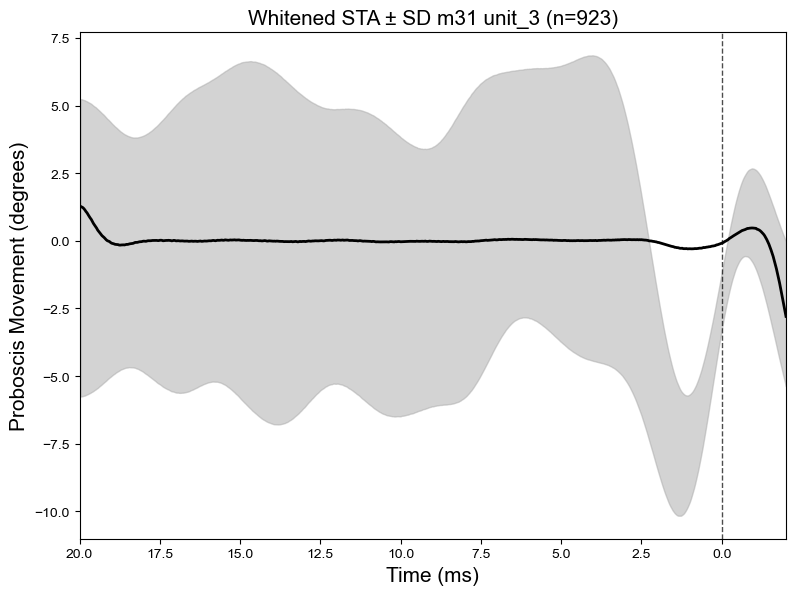

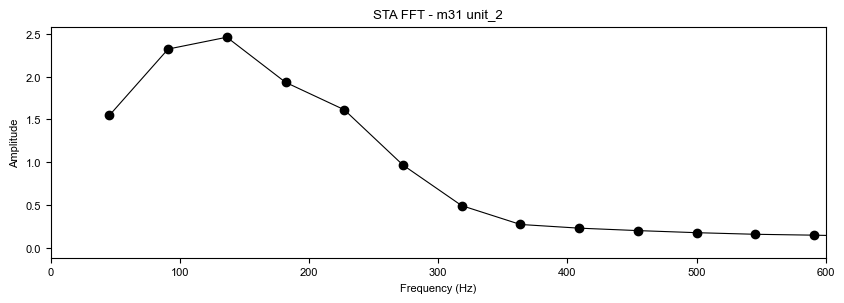

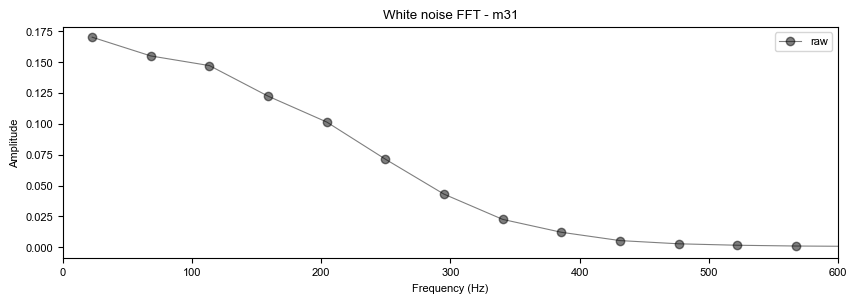

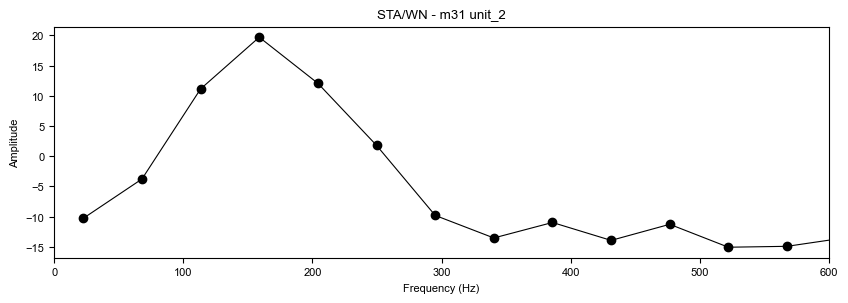

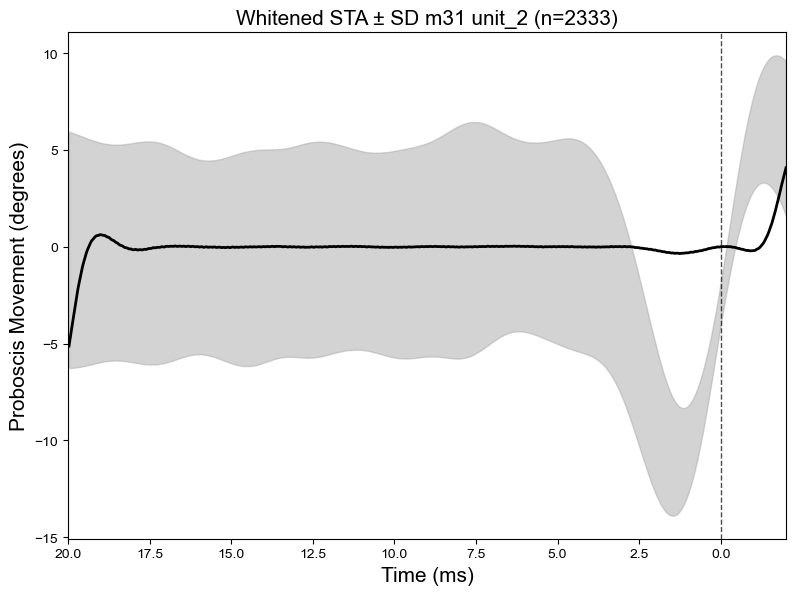

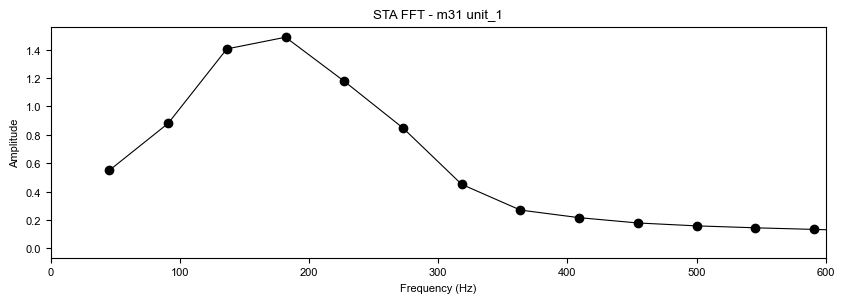

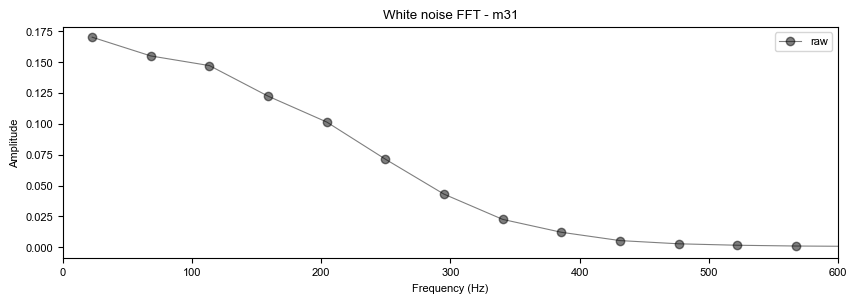

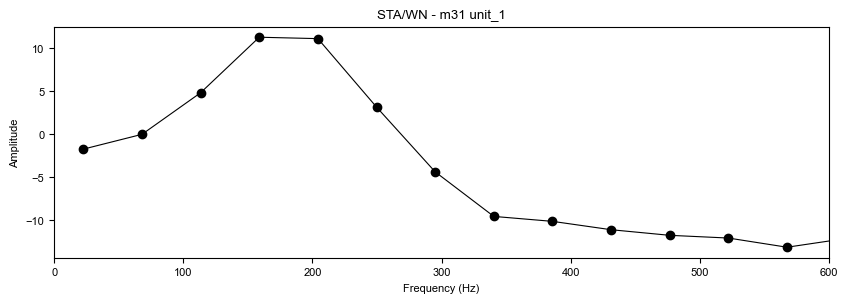

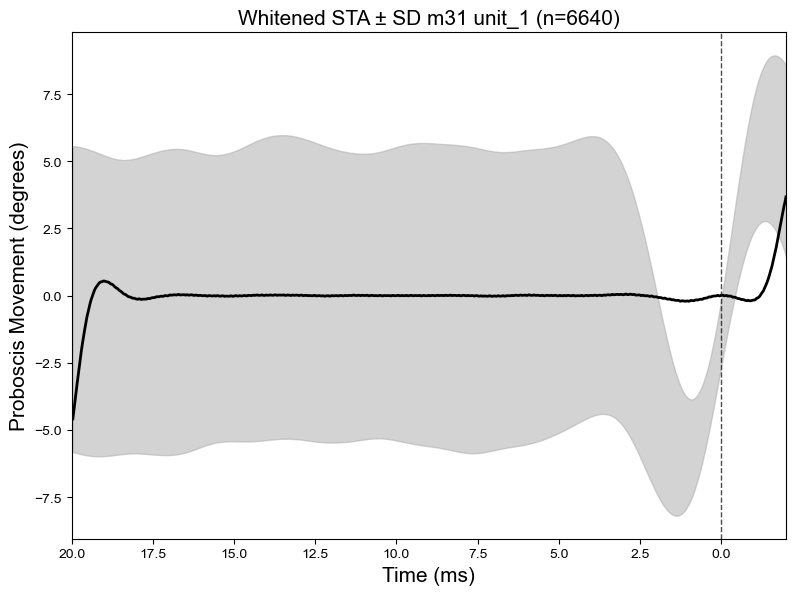

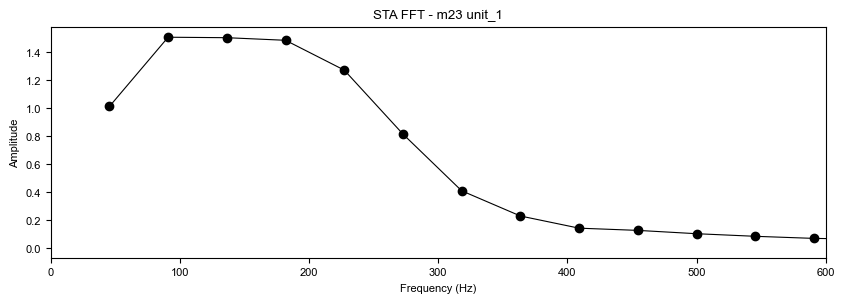

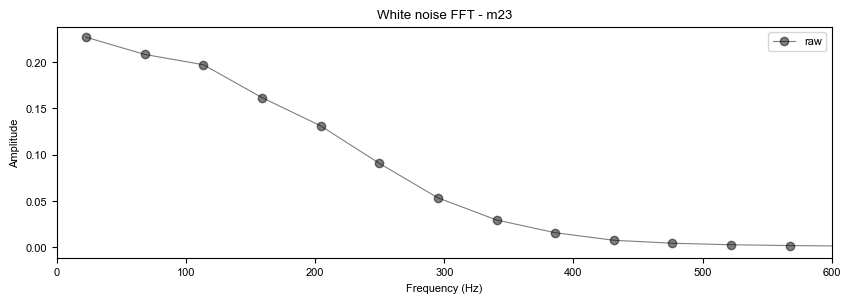

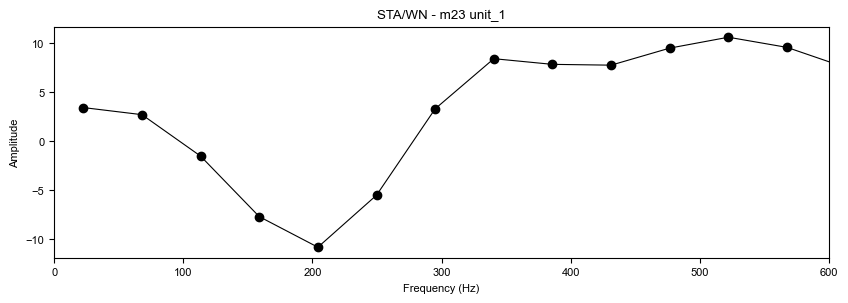

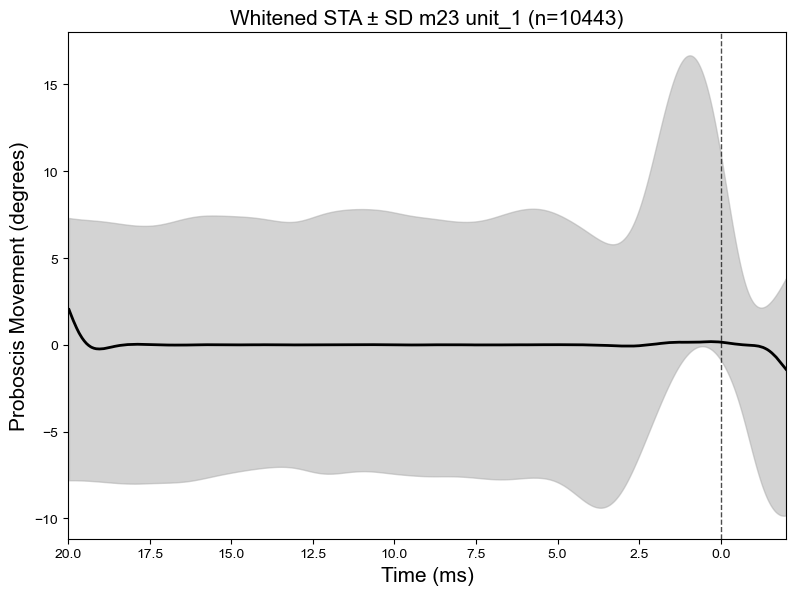

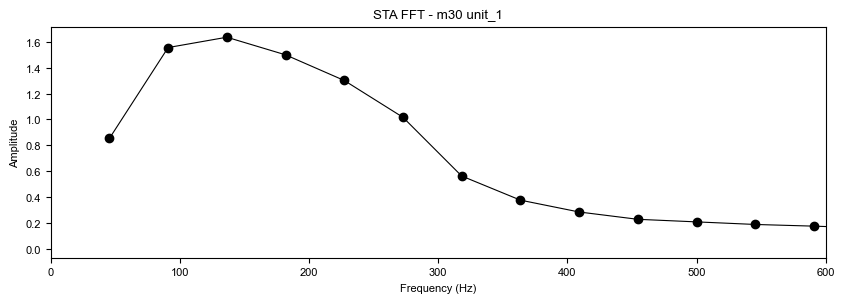

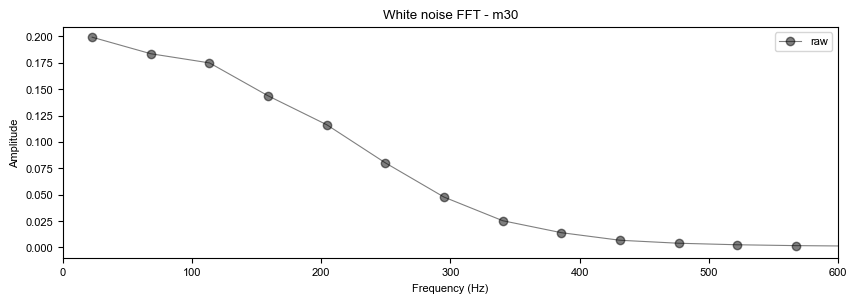

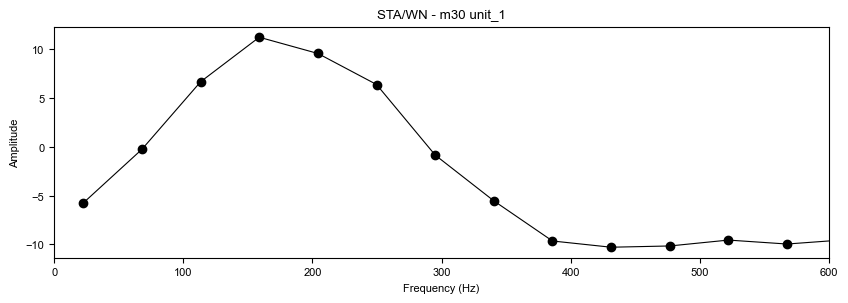

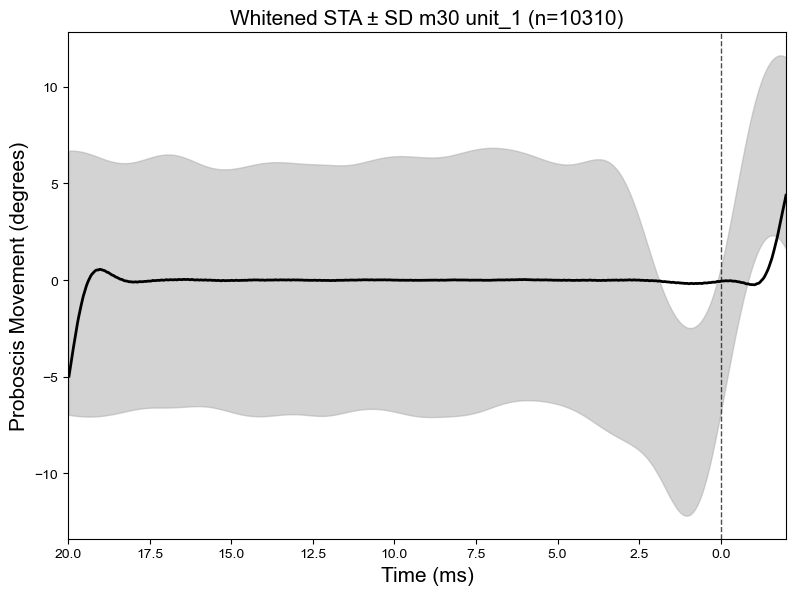

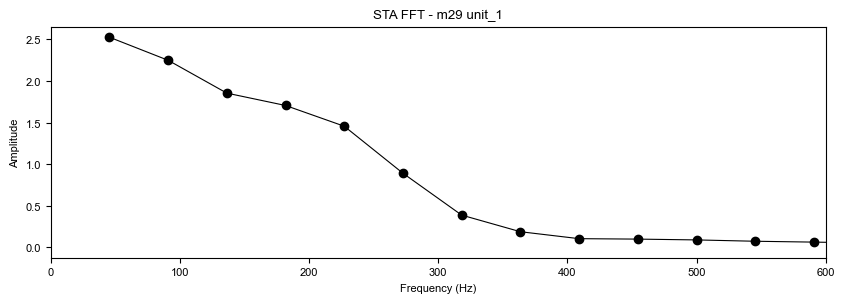

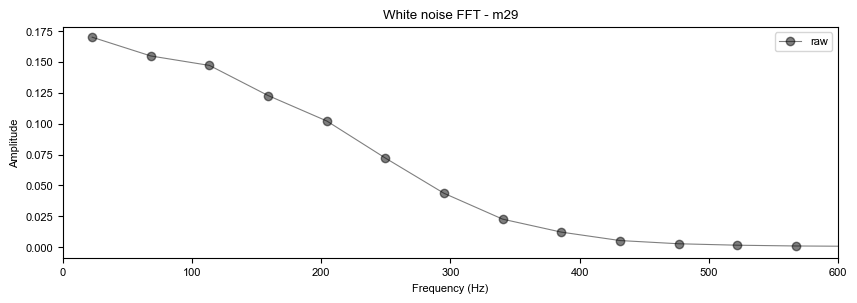

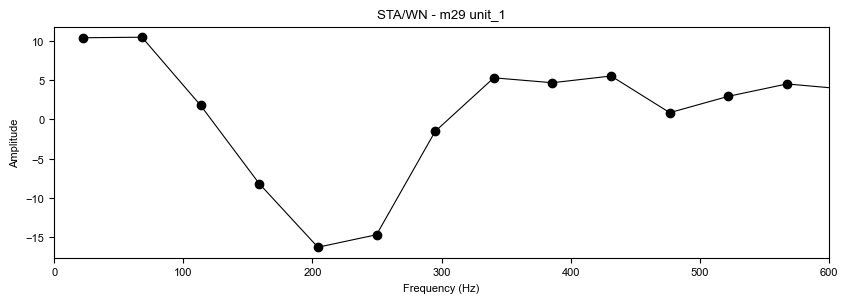

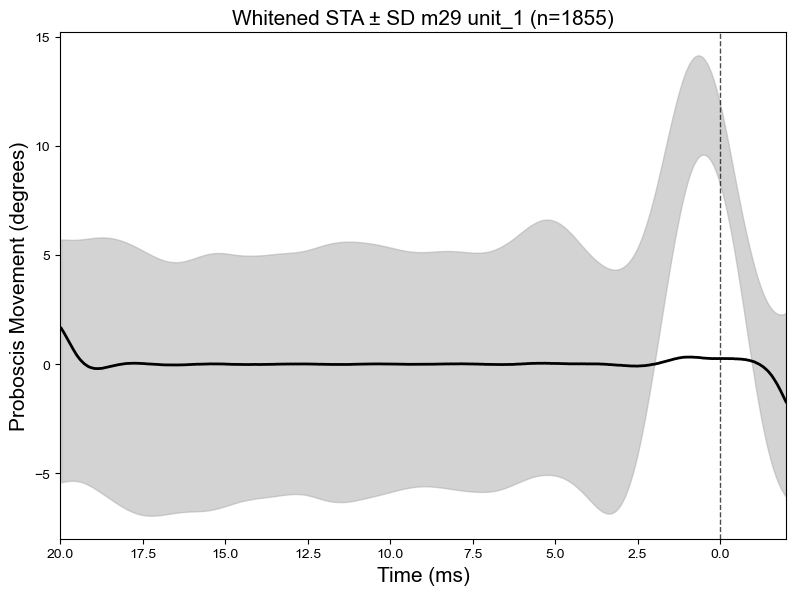

In [11]:
for filepath in model_files:
    name = os.path.basename(filepath).split('_')[0]
    unitID = "_".join(os.path.basename(filepath).split('_')[1:3])
    
    # load STA
    with open(filepath, 'rb') as f:
        savedModel = pickle.load(f)
    sta = savedModel[1].values
    sta_error = savedModel[2].values
    n_spikes = len(savedModel[0])
    
    # FFT of STA
    freqs_sta = fftfreq(len(sta), d=1/Fs)
    pos_sta = freqs_sta > 0
    fft_sta = fft(sta, norm='forward')
    fft_sta *= 2
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_sta[pos_sta], np.abs(fft_sta)[pos_sta], 'o-k', linewidth=0.8)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.xlim(0, 600)
    plt.title(f'STA FFT - {name} {unitID}')
    plt.show()
    plt.close()
    
    # load matching white noise
    wn_filepath = [f for f in wn_files if name in f][0]
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    # FFT of white noise and downsample to STA resolution
    fft_wn_full = np.abs(fft(WhiteNoise, norm='forward'))
    fft_wn_full *= 2
    freqs_wn_full = fftfreq(len(WhiteNoise), d=1/Fs)
    
    chunk = len(fft_wn_full) // len(sta)
    fft_wn_ds = np.array([fft_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(len(sta))])
    freqs_wn_ds = np.array([freqs_wn_full[i*chunk:(i+1)*chunk].mean() for i in range(len(sta))])
    pos = freqs_wn_ds > 0
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_wn_ds[pos], fft_wn_ds[pos], 'o-k', linewidth=0.8, alpha=0.5, label='raw')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.xlim(0, 600)
    plt.legend()
    plt.title(f'White noise FFT - {name}')
    plt.show()
    plt.close()
    
    # spectral whitening with regularisation
    lambda_reg = 0.01 * np.max(fft_wn_ds)
    fft_sta_whitened = fft_sta / (fft_wn_ds + lambda_reg)
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_wn_ds[pos], fft_sta_whitened[pos], 'o-k', linewidth=0.8)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.xlim(0, 600)
    plt.title(f'STA/WN - {name} {unitID}')
    plt.show()
    plt.close()
    
    # inverse FFT to get whitened STA
    sta_whitened = np.real(ifft(fft_sta_whitened))
    
    # plot whitened STA exactly like original STA
    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs)
    t_ms = time_axis * 1000
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.fill_between(t_ms, np.flip(sta - sta_error, axis=0), np.flip(sta + sta_error, axis=0),
                    color='darkgrey', alpha=0.5)
    ax.plot(t_ms, np.flip(sta_whitened), 'k', linewidth=2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax.set_xlim(20, -2)
    ax.set_xlabel('Time (ms)', fontsize=15)
    ax.set_ylabel('Proboscis Movement (degrees)', fontsize=15)
    ax.set_title(f'Whitened STA ± SD {name} {unitID} (n={n_spikes})', fontsize=15)
    ax.tick_params(labelsize=10)
    plt.tight_layout()
    plt.show()
    plt.close()

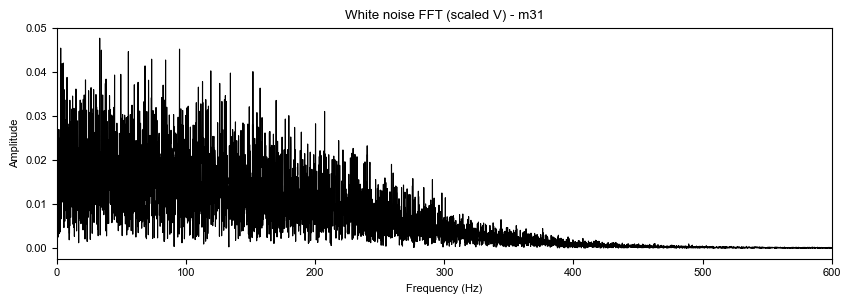

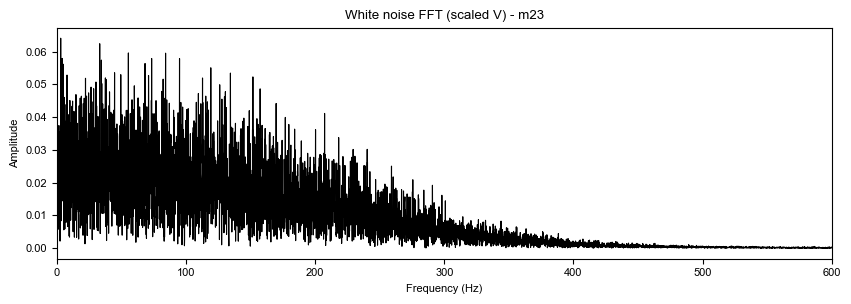

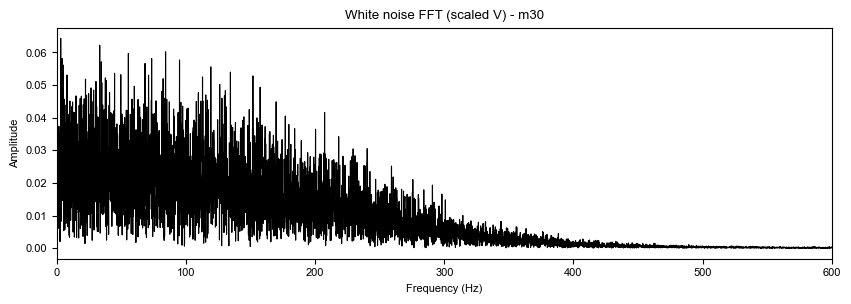

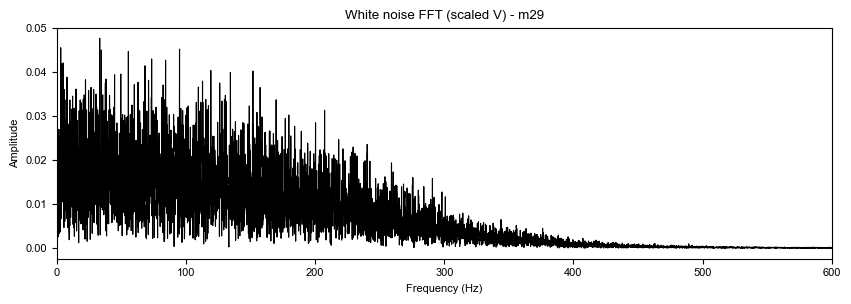

In [74]:
wn_files_scaled = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_timeStamps_scaled.pickle')

for filepath in model_files:
    name = os.path.basename(filepath).split('_')[0]
    unitID = "_".join(os.path.basename(filepath).split('_')[1:3])
    
    if unitID != 'unit_1':
        continue
    
    wn_filepath = [f for f in wn_files_scaled if name in f][0]
    with open(wn_filepath, 'rb') as f:
        wn_data = pickle.load(f)
    WhiteNoise = np.array(wn_data[2])
    
    fft_wn_full = np.abs(fft(WhiteNoise)) / len(WhiteNoise) * 2
    freqs_wn_full = fftfreq(len(WhiteNoise), d=1/Fs)
    pos = freqs_wn_full > 0
    
    plt.figure(figsize=(10, 3))
    plt.plot(freqs_wn_full[pos], fft_wn_full[pos], 'k', linewidth=0.8)
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Amplitude')
    plt.xlim(0, 600)
    plt.title(f'White noise FFT (scaled V) - {name}')
    plt.show()
    plt.close()

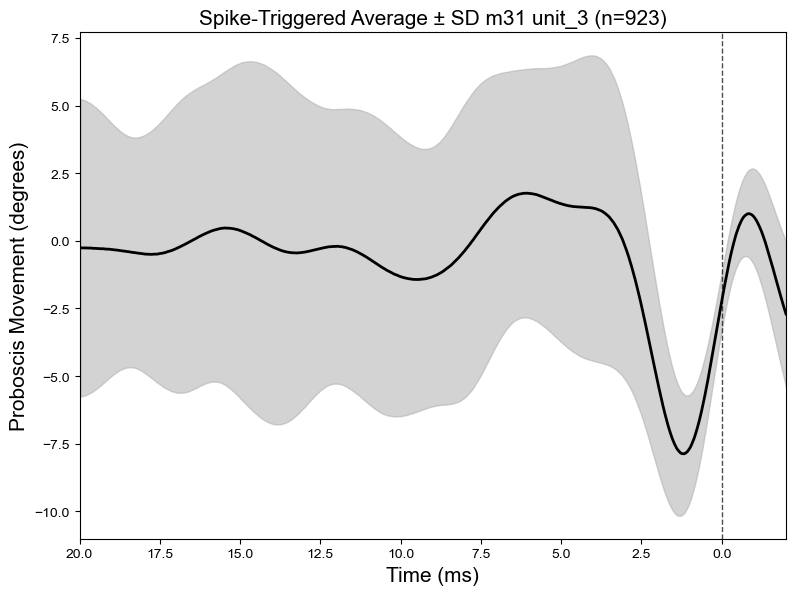

In [10]:
filepath = model_files[0]  # just first file for now
with open(filepath, 'rb') as f:
    savedModel = pickle.load(f)

name = os.path.basename(filepath).split('_')[0]
unitID = "_".join(os.path.basename(filepath).split('_')[1:3])

sta = savedModel[1].values
sta_error = savedModel[2].values

n_spikes = len(savedModel[0])
time_axis = np.arange(-TimePost, TimeHistory, 1/Fs)
t_ms = time_axis * 1000

fig, ax = plt.subplots(figsize=(8, 6))
ax.fill_between(t_ms, np.flip(sta - sta_error, axis=0), np.flip(sta + sta_error, axis=0),
                color='darkgrey', alpha=0.5)
ax.plot(t_ms, np.flip(sta), 'k', linewidth=2, label='Mean (STA)')
ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
ax.set_xlim(20, -2)
ax.set_xlabel('Time (ms)', fontsize=15)
ax.set_ylabel('Proboscis Movement (degrees)', fontsize=15)
ax.set_title(f'Spike-Triggered Average ± SD {name} {unitID} (n={n_spikes})', fontsize=15)
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.show()
plt.close()



In [7]:
print(model_files[0])

./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/m31_unit_3_EncodingModel.pickle


In [8]:
print(type(savedModel[1]))
print(savedModel[1])

<class 'pandas.core.series.Series'>
0     -0.260757
1     -0.257716
2     -0.261606
3     -0.261952
4     -0.263046
         ...   
655   -2.174865
656   -2.314716
657   -2.447824
658   -2.579046
659   -2.700775
Length: 660, dtype: float64


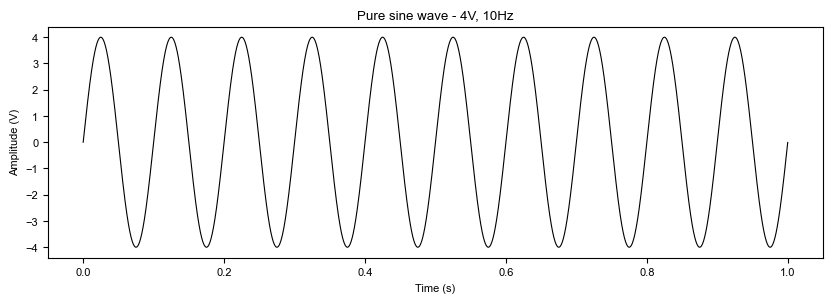

In [12]:
t = np.arange(0, 1, 1/Fs)  # 1 second
sine = 4 * np.sin(2 * np.pi * 10 * t)  # 4V amplitude, 10Hz

plt.figure(figsize=(10, 3))
plt.plot(t, sine, 'k', linewidth=0.8)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (V)')
plt.title('Pure sine wave - 4V, 10Hz')
plt.show()